In [1]:
import pandas as pd
import numpy as np
import random
import seaborn as sns

# Graph Plotting of Probability Distributions

### 1>. Probability Mass Function(PMF)

In [2]:
# How to plot graph 

# Example 1>. for one dice


In [2]:
L = []
for i in range(10000):
    L.append(random.randint(1,6))

In [3]:
len(L)

10000

In [4]:
L[:5]

[6, 4, 4, 4, 4]

In [5]:
s = (pd.Series(L).value_counts() / pd.Series(L).value_counts().sum()).sort_index()

<Axes: >

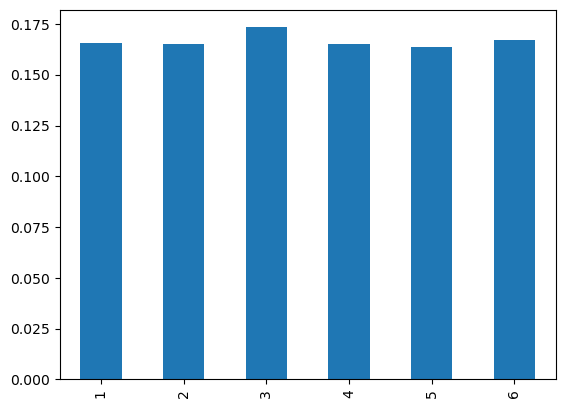

In [6]:
s.plot(kind='bar')

In [7]:
# Example 2>. Two dice

L = []
for i in range(10000):
    a = random.randint(1,6)
    b = random.randint(1,6)

    L.append(a + b)

In [8]:
L[:5]

[7, 10, 6, 6, 7]

In [9]:
s = (pd.Series(L).value_counts() / pd.Series(L).value_counts().sum()).sort_index()

In [10]:
s

2     0.0270
3     0.0573
4     0.0814
5     0.1146
6     0.1408
7     0.1687
8     0.1367
9     0.1107
10    0.0818
11    0.0530
12    0.0280
Name: count, dtype: float64

<Axes: >

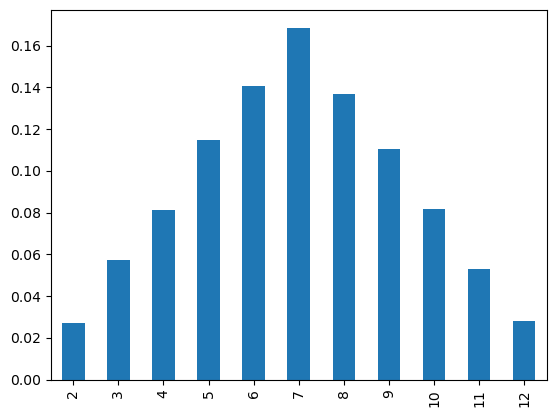

In [11]:
s.plot(kind='bar')

### 2>. Cumulative Distribution Function (CDF) to (PMF)

In [12]:
# Formula   f(x) = P(x <= x)

In [13]:
np.cumsum(s)

2     0.0270
3     0.0843
4     0.1657
5     0.2803
6     0.4211
7     0.5898
8     0.7265
9     0.8372
10    0.9190
11    0.9720
12    1.0000
Name: count, dtype: float64

<Axes: >

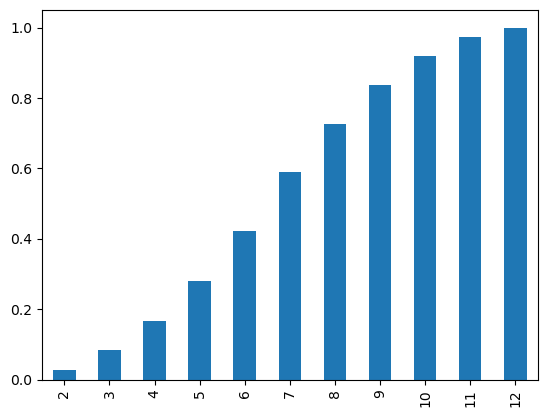

In [14]:
np.cumsum(s).plot(kind='bar')

### 3>. Probability Density Function (PDF)

#### 1>. Parametric Density Estimation

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import normal

sample = normal(loc = 50, scale = 5, size = 1000)

In [16]:
sample.mean()

np.float64(50.155274891455626)

In [17]:
sample.std()

np.float64(5.175778033635961)

(array([  3.,  14.,  80., 159., 227., 255., 165.,  67.,  23.,   7.]),
 array([33.11808989, 36.48877231, 39.85945473, 43.23013716, 46.60081958,
        49.971502  , 53.34218443, 56.71286685, 60.08354927, 63.4542317 ,
        66.82491412]),
 <BarContainer object of 10 artists>)

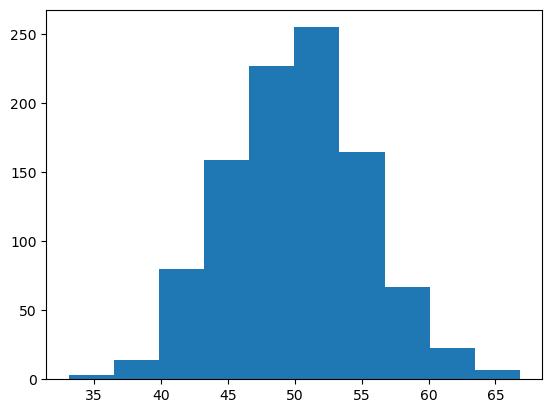

In [18]:
# Plot histogram to understand the distribution of data

plt.hist(sample, bins=10)

In [19]:
# calculate sample mean and sample std dev

sample_mean = sample.mean()
sample_std = sample.std()

In [20]:
# Fit the distribution in above parameter

from scipy.stats import norm

dist = norm(sample_mean, sample_std)

In [21]:
sample.max()

np.float64(66.82491411928211)

In [22]:
sample.min()

np.float64(33.1180898869061)

In [23]:
values = np.linspace(sample.min(), sample.max(), 100)

In [24]:
# Mean of data = muy
# STD of data = 

In [25]:
probabilities = [dist.pdf(value) for value in values]

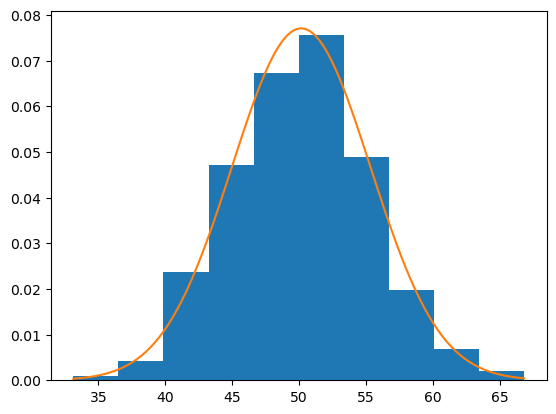

In [26]:
# Plot the histogram and pdf

plt.hist(sample, bins=10, density=True)
plt.plot(values, probabilities)

C:\Users\Hemant\AppData\Local\Temp\ipykernel_10140\3174192582.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

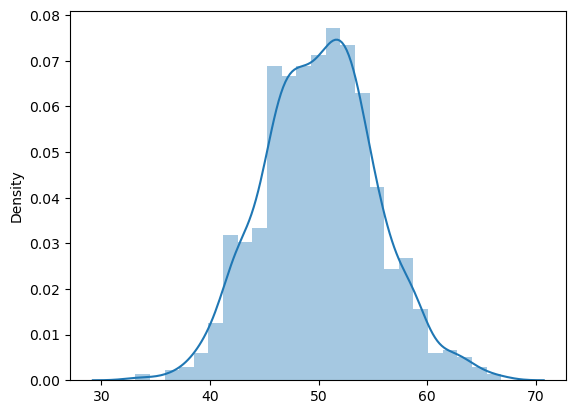

In [27]:
# Same graph with seaborn 

sns.distplot(sample)

#### 2>. Non-Parametric Density Estimation

In [28]:
# KDE (Kernel Density Estimation)

# In KDE ---> STD  ----> bandwidth(bw)

In [29]:
# Genrate a sample

sample1 = normal(loc=20, scale=5, size=300)
sample2 = normal(loc=40, scale=5, size=700)

sample = np.hstack((sample1, sample2))

In [30]:
sample

array([16.83013396, 23.29799192, 14.30660722, 26.89528899, 14.52583709,
       10.44378353, 14.25954518, 24.65115864, 23.07655819, 30.43124206,
       24.14029885, 16.89241175, 15.03431432, 17.60944549, 17.09363   ,
       18.56916291, 18.25542638, 21.63137022, 21.45100455, 19.80921572,
       20.67989892, 28.14139093, 13.41683779, 19.72838265, 22.17798353,
       12.57537782, 19.24348954, 13.02176169, 24.94635543, 11.89443465,
       27.91659807, 17.11755218, 20.97795351, 19.96293572, 20.64218671,
       26.4404491 , 22.22078766, 27.87421953, 24.13728846, 19.70387263,
       19.77541182, 16.58532673, 28.03607583, 25.77663564, 19.86032532,
       14.40813738, 13.95365058, 22.19860433, 19.22409814, 13.27591431,
       23.29862339, 29.53828455, 24.21274443, 30.33658698, 21.24485243,
       19.06888374, 18.8973868 , 14.26073705, 20.11365901, 20.12588665,
       21.09323346, 28.04060474, 23.23593207, 18.01194664, 24.99786276,
       16.62130106, 11.9500657 , 22.57668504, 28.33001298, 20.46

(array([ 2.,  1.,  4.,  5.,  3.,  9.,  9., 13., 10., 14., 23., 21., 20.,
        30., 27., 19., 22., 17., 15., 10.,  6., 17., 11., 17., 14., 12.,
        26., 20., 34., 49., 55., 61., 62., 54., 52., 48., 50., 39., 31.,
        24., 16.,  7.,  7.,  7.,  2.,  3.,  1.,  0.,  0.,  1.]),
 array([ 6.47001924,  7.48870439,  8.50738954,  9.52607469, 10.54475984,
        11.56344499, 12.58213014, 13.60081529, 14.61950044, 15.63818559,
        16.65687074, 17.67555589, 18.69424104, 19.71292619, 20.73161134,
        21.75029649, 22.76898164, 23.78766679, 24.80635195, 25.8250371 ,
        26.84372225, 27.8624074 , 28.88109255, 29.8997777 , 30.91846285,
        31.937148  , 32.95583315, 33.9745183 , 34.99320345, 36.0118886 ,
        37.03057375, 38.0492589 , 39.06794405, 40.0866292 , 41.10531435,
        42.1239995 , 43.14268465, 44.1613698 , 45.18005495, 46.19874011,
        47.21742526, 48.23611041, 49.25479556, 50.27348071, 51.29216586,
        52.31085101, 53.32953616, 54.34822131, 55.36690646,

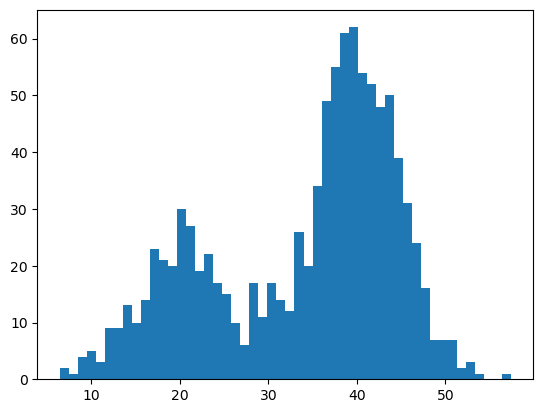

In [31]:
# Plot histogram bins =50

plt.hist(sample, bins=50)

In [32]:
from sklearn.neighbors import KernelDensity

model = KernelDensity(bandwidth=3, kernel='gaussian')

In [33]:
# Covert data to a 2D array

sample = sample.reshape((len(sample), 1))
model.fit(sample)

KernelDensity(bandwidth=3)

In [34]:
values = np.linspace(sample.min(), sample.max(), 100)
values = values.reshape((len(values),1))

In [35]:
probabilities = model.score_samples(values)
probabilities = np.exp(probabilities)

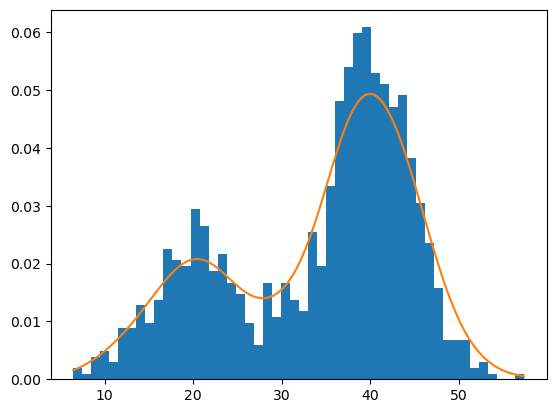

In [36]:
plt.hist(sample, bins=50, density=True)
plt.plot(values[:], probabilities)
plt.show()

<Axes: ylabel='Density'>

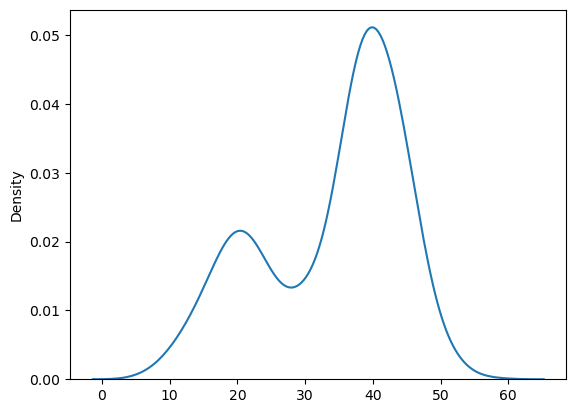

In [37]:
# With seaborn

sns.kdeplot(sample.reshape(1000),)

<Axes: ylabel='Density'>

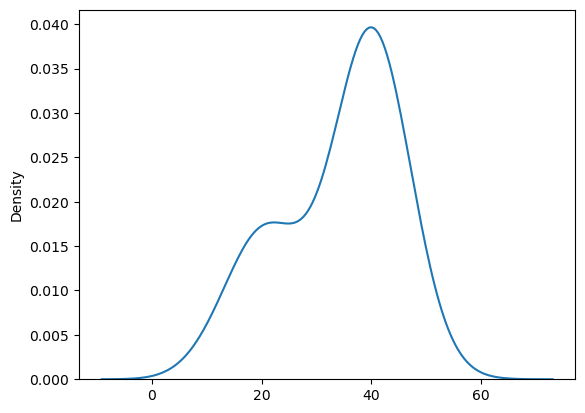

In [38]:
sns.kdeplot(sample.reshape(1000), bw_adjust=2)

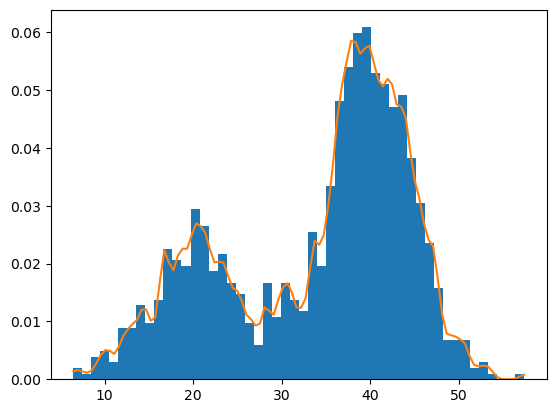

In [39]:
# bandwidth = 0.5

from sklearn.neighbors import KernelDensity
model = KernelDensity(bandwidth=0.5, kernel='gaussian')

# Covert data to a 2D array
sample = sample.reshape((len(sample), 1))
model.fit(sample)

values = np.linspace(sample.min(), sample.max(), 100)
values = values.reshape((len(values),1))

probabilities = model.score_samples(values)
probabilities = np.exp(probabilities)

plt.hist(sample, bins=50, density=True)
plt.plot(values[:], probabilities)
plt.show()

<Axes: ylabel='Density'>

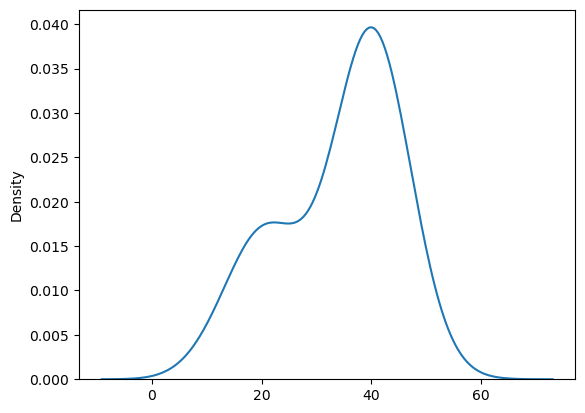

In [40]:
# Same with seaborn 
sns.kdeplot(sample.reshape(1000), bw_adjust=2)

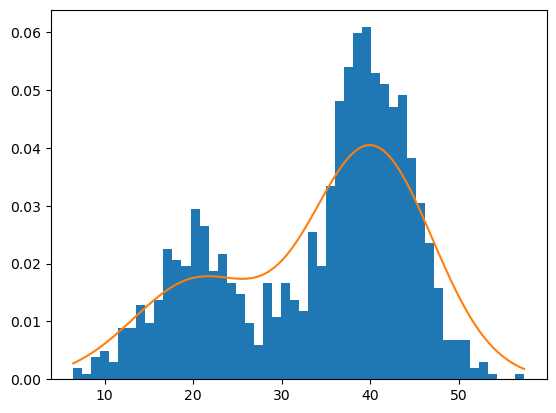

In [41]:
# bandwidth = 5

# bandwidth = 0.5

from sklearn.neighbors import KernelDensity
model = KernelDensity(bandwidth=5, kernel='gaussian')

# Covert data to a 2D array
sample = sample.reshape((len(sample), 1))
model.fit(sample)

values = np.linspace(sample.min(), sample.max(), 100)
values = values.reshape((len(values),1))

probabilities = model.score_samples(values)
probabilities = np.exp(probabilities)

plt.hist(sample, bins=50, density=True)
plt.plot(values[:], probabilities)
plt.show()

# 4> Cumulative Distribution Function (CDF)

In [42]:
# How to use PDF in data science (give probability of exact point)

In [43]:
df = sns.load_dataset("iris")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='petal_length', ylabel='Density'>

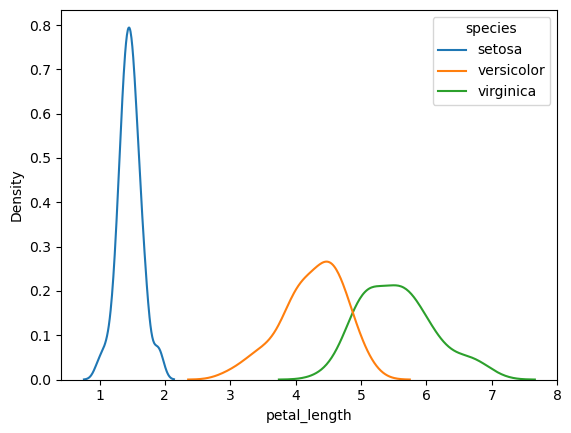

In [44]:
sns.kdeplot(data=df, x='petal_length', hue='species')

<Axes: xlabel='petal_width', ylabel='Density'>

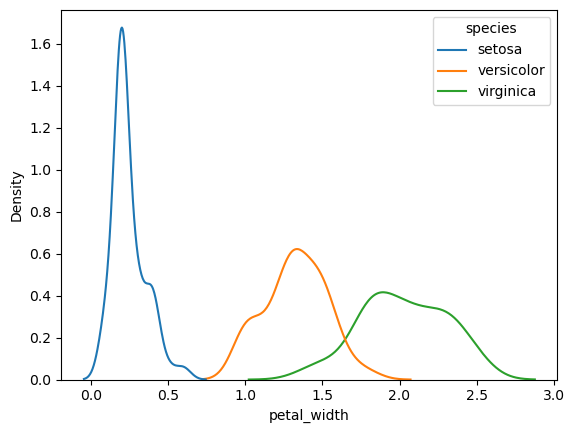

In [45]:
sns.kdeplot(data=df, x='petal_width', hue='species')

<Axes: xlabel='sepal_length', ylabel='Density'>

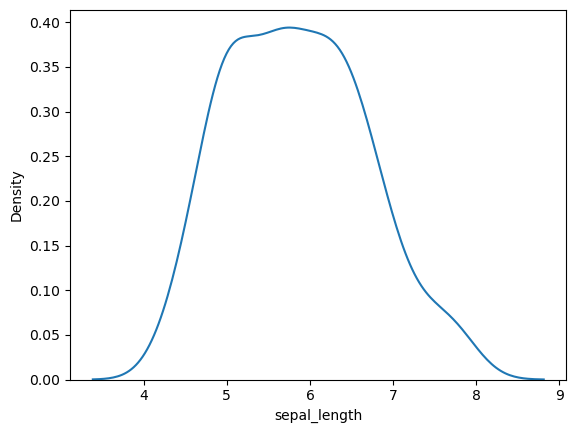

In [46]:
sns.kdeplot(df['sepal_length']) # PDF

<Axes: xlabel='sepal_length', ylabel='Density'>

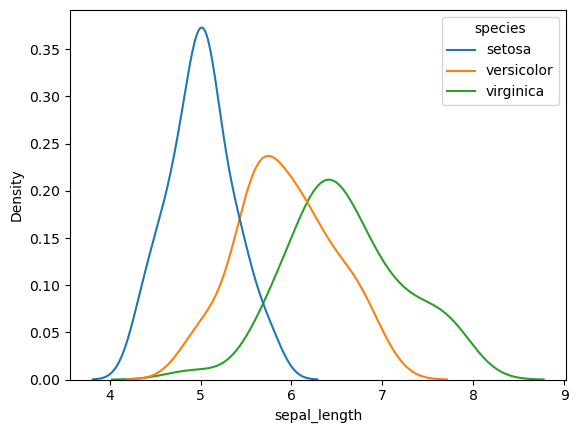

In [47]:
sns.kdeplot(data=df, x='sepal_length', hue='species')

<Axes: xlabel='sepal_width', ylabel='Density'>

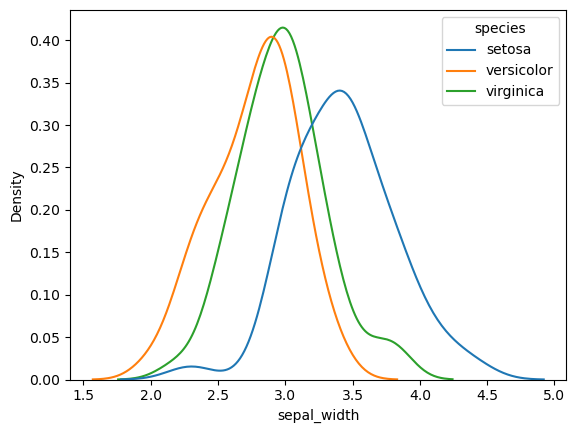

In [48]:
sns.kdeplot(data=df, x='sepal_width', hue='species')

In [49]:
# 2>. How to use CDF in data science (giev probability till point in range)

<Axes: xlabel='petal_width', ylabel='Density'>

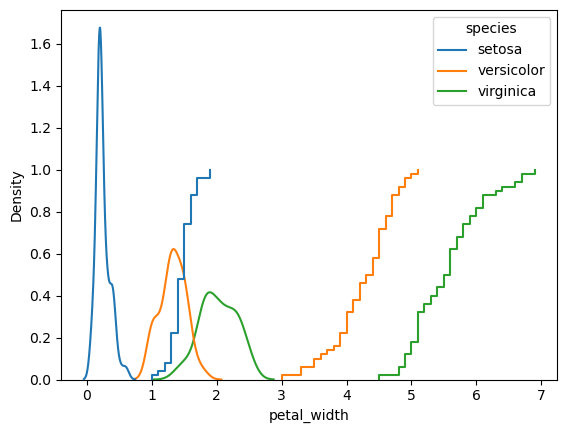

In [51]:
sns.kdeplot(data=df, x='petal_width', hue='species')

sns.ecdfplot(data=df, x='petal_length', hue='species')

## 2D Density Plots

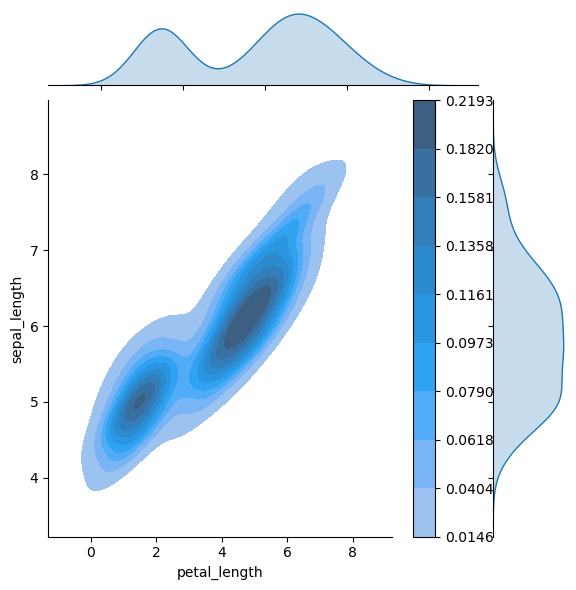

In [52]:
sns.jointplot(data=df, x='petal_length', y='sepal_length', kind='kde', fill=True, cbar=True) # 